# 51. N-Queens
**Difficulty:** 🔴 Hard · **Topic:** Backtracking · **Pattern:** [Partition and Placement](README.md) · **LeetCode:** https://leetcode.com/problems/n-queens/

## 💡 Concepts

**Core concept(s):** **backtracking placement** — fill the board one row at a time; in each row, choose *which column* the queen goes in, check it is safe, recurse to the next row, then remove it.

**Why it applies here:**
- Two queens in the same row attack each other, so every row holds **exactly one** queen. That turns "place `n` queens anywhere" into "pick one column per row".
- Whether a square is safe depends only on the queens already placed above it, so the check can run **before** the queen is placed and cut whole sub-trees.
- We must return **every** valid board, so every branch that survives the check is explored.

**Key intuition:**
- A queen at `(r, c)` blocks its column `c`, its `\` diagonal, and its `/` diagonal.
- Every square on one `\` diagonal has the same `r - c`; every square on one `/` diagonal has the same `r + c`.
- Keep three sets — `cols`, `diag` (`r - c`), `anti` (`r + c`) — and "is `(r, c)` safe?" is three `O(1)` lookups.

---

### 📚 What is Recursion / DFS?
- **Recursion** is a function that solves a problem by calling itself on a smaller part of it.
- **Depth-first search (DFS)** follows one choice all the way down before trying the next choice.
- Python keeps each pending call on the **call stack**; when a call returns, execution resumes in its caller exactly where it left off.
- **Complexity:** the stack is as deep as the longest chain of calls — here `n` (one call per row).

### 📚 What is Backtracking?
- **Backtracking** is DFS over *decisions*: make a choice, recurse, then **undo** the choice and try the next one.
- The shared state (the board and the three sets) is modified in place, so the un-choose line must undo **every** piece the choose line changed.
- **Pruning:** a test placed *before* the choice skips whole sub-trees that cannot lead to an answer.
- **In Python:** a nested `def backtrack(r)` that closes over the board and the sets.

### 📚 What is a Hash Set?
- A **set** stores unique values with no order.
- It hashes each value to a slot in an internal array, so it can jump straight to where the value would be.
- `add`, `remove`, and `in` are **O(1) on average**.
- **In Python:** `set()`; here it holds blocked columns and blocked diagonal ids.

### 📚 What is a Permutation?
- A **permutation** of `0..n-1` is one ordering of those numbers; there are `n!` of them (`4! = 24`, `8! = 40320`).
- Read `perm[r]` as "the column of the queen in row `r`": rows are distinct by position and columns are distinct because a permutation never repeats a value.
- So only the diagonals still need checking.
- **In Python:** `itertools.permutations(range(n))` yields them one at a time.

---

**Prerequisite knowledge:**
- The choose → explore → un-choose loop from [Subsets](../01_Subsets/README.md) and [Combinations](../02_Combinations/README.md).
- [Palindrome Partitioning](palindrome_partitioning.ipynb): the same "choose where the next piece goes, check, recurse, undo" shape on a string.

## 📝 Problem

Place `n` queens on an `n × n` chessboard so that **no two queens attack each other** (no shared row, column, or diagonal). Return **all** distinct solutions, each as a list of `n` strings where `'Q'` is a queen and `'.'` is empty (any order).

**Example 1**
```
n = 4  ->  [[".Q..",       [["..Q.",
             "...Q",         "Q...",
             "Q...",         "...Q",
             "..Q."],        ".Q.."]]
```

**Example 2**
```
n = 1  ->  [["Q"]]
```

**Constraints:** `1 <= n <= 9`.

Number of solutions for `n = 1..8`: `1, 0, 0, 2, 10, 4, 40, 92`.

> Three approaches: try every permutation of columns and validate (brute force), backtracking with a scan over the placed queens, and backtracking with three sets for `O(1)` checks (the pattern template).

In [1]:
from typing import List
from itertools import permutations

def board_from_cols(cols: List[int]) -> List[str]:
    """cols[r] = column of the queen in row r  ->  the LeetCode board format."""
    n = len(cols)
    return ["." * c + "Q" + "." * (n - c - 1) for c in cols]

### Approach 1 — Brute Force: every permutation of columns, then validate

**Idea:**
1. One queen per row and one per column means the board is a permutation: `perm[r]` is the column of row `r`'s queen.
2. Generate all `n!` permutations.
3. Keep a permutation only if all `n` values of `r - c` are distinct (no shared `\` diagonal) and all `n` values of `r + c` are distinct (no shared `/` diagonal).

**Time complexity:** `O(n · n!)` — `n!` permutations, each validated in `O(n)`. Every permutation is built in full, even when its first two queens already attack each other.

**Space complexity:** `O(n)` for one permutation and the two diagonal sets (output aside).

In [2]:
def solve_n_queens_brute(n: int) -> List[List[str]]:
    out = []
    for perm in permutations(range(n)):                  # rows and columns distinct by construction
        if len({r - c for r, c in enumerate(perm)}) == n and \
           len({r + c for r, c in enumerate(perm)}) == n:  # no two queens share a diagonal
            out.append(board_from_cols(list(perm)))
    return out

### Approach 2 — Backtracking, scan the placed queens

**Idea:**
1. Place queens row by row; `queens[r]` is the column chosen for row `r`.
2. Before placing at `(r, c)`, scan every queen above: same column (`pc == c`) or same diagonal (`|pr - r| == |pc - c|`) means unsafe.
3. If safe: choose `queens.append(c)`, explore `backtrack(r + 1)`, un-choose `queens.pop()`.

**Time complexity:** `O(n · n!)` upper bound — row `r` has at most `n - r` free columns, so at most `n!` placements, and each safety check scans up to `n` queens. Pruning makes the real count far smaller (see the benchmark).

**Space complexity:** `O(n)` — recursion depth `n` plus the `queens` list.

In [3]:
def solve_n_queens_scan(n: int) -> List[List[str]]:
    out, queens = [], []                                 # queens[r] = column of the queen in row r
    def safe(r, c):
        for pr, pc in enumerate(queens):                 # O(r) scan of the queens above
            if pc == c or abs(pr - r) == abs(pc - c):    # same column, or same diagonal
                return False
        return True
    def backtrack(r):
        if r == n:
            out.append(board_from_cols(queens))
            return
        for c in range(n):
            if not safe(r, c):                           # PRUNE
                continue
            queens.append(c)                             # CHOOSE
            backtrack(r + 1)                             # EXPLORE
            queens.pop()                                 # UN-CHOOSE
    backtrack(0)
    return out

### Approach 3 — Backtracking with column / diagonal sets (optimal · pattern template)

**Idea:** the [Partition and Placement](README.md) template. The state is `r`, the row that needs a queen.
1. If `r == n`, every row has a queen: record the board.
2. Otherwise try every column `c` of row `r`.
3. **Prune:** skip `c` if `c in cols`, `(r - c) in diag`, or `(r + c) in anti` — three `O(1)` lookups.
4. **Choose:** add `c`, `r - c`, `r + c` to the sets and put `'Q'` on the board. **Explore** `backtrack(r + 1)`. **Un-choose:** remove all three and put `'.'` back.

**Time complexity:** `O(n!)` upper bound on placements (row `r` has at most `n - r` free columns), each check `O(1)`, plus `O(n²)` to copy each solution board.

**Space complexity:** `O(n²)` for the working board, `O(n)` for the three sets and the recursion (output aside).

> Same search as Approach 2, but the safety check drops from `O(n)` to `O(1)`. This is the shape interviewers expect for N-Queens.

In [4]:
def solve_n_queens_sets(n: int) -> List[List[str]]:
    out, cols, diag, anti = [], set(), set(), set()      # blocked columns, r-c ids, r+c ids
    board = [["."] * n for _ in range(n)]
    def backtrack(r):
        if r == n:                                       # a queen in every row
            out.append(["".join(row) for row in board])  # record a COPY of the board
            return
        for c in range(n):                               # which column in row r?
            if c in cols or (r - c) in diag or (r + c) in anti:
                continue                                 # PRUNE: attacked by a queen above
            cols.add(c); diag.add(r - c); anti.add(r + c); board[r][c] = "Q"        # CHOOSE
            backtrack(r + 1)                                                        # EXPLORE
            cols.remove(c); diag.remove(r - c); anti.remove(r + c); board[r][c] = "."   # UN-CHOOSE
    backtrack(0)
    return out

In [5]:
# Correctness check
expected_4 = [[".Q..", "...Q", "Q...", "..Q."], ["..Q.", "Q...", "...Q", ".Q.."]]
for f in (solve_n_queens_brute, solve_n_queens_scan, solve_n_queens_sets):
    assert sorted(f(4)) == sorted(expected_4), f.__name__       # LeetCode example 1
    assert f(1) == [["Q"]], f.__name__                         # LeetCode example 2
print("n = 4:")
for board in solve_n_queens_sets(4):
    print("   ", board)

counts = [len(solve_n_queens_sets(n)) for n in range(1, 9)]
print("solution counts for n = 1..8:", counts)
assert counts == [1, 0, 0, 2, 10, 4, 40, 92]                   # the classic sequence

# All three approaches return the same set of boards for n = 1..8
for n in range(1, 9):
    a, b, c = solve_n_queens_brute(n), solve_n_queens_scan(n), solve_n_queens_sets(n)
    assert sorted(a) == sorted(b) == sorted(c), n
    for board in c:                                            # each board really is valid
        qs = [row.index("Q") for row in board]
        assert len(set(qs)) == n
        assert len({r - q for r, q in enumerate(qs)}) == n and len({r + q for r, q in enumerate(qs)}) == n
print("n = 1..8: all three approaches agree, every board is valid")
print("\nAll tests passed")

n = 4:
    ['.Q..', '...Q', 'Q...', '..Q.']
    ['..Q.', 'Q...', '...Q', '.Q..']
solution counts for n = 1..8: [1, 0, 0, 2, 10, 4, 40, 92]
n = 1..8: all three approaches agree, every board is valid

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. The search space here grows like `n!`, so doubling `n` is out of reach (`n = 18` would take hours). Instead we grow `n` by **+1** and read the ratio per extra row:

| Theoretical | Ratio when `n` → `n + 1` |
|-------------|--------------------------|
| `O(n!)` (no pruning) | ≈ **n + 1** (each extra row multiplies the permutations by `n + 1`) |
| backtracking with pruning | smaller than `n + 1`, because attacked squares cut branches early |

(The helper's last line describes ratios for *doubling* sizes; ignore it here, since our sizes step by +1.)

The input is just `n`, and every approach always searches the whole board for all solutions, so `make_worst_case(n)` is simply `(n,)`. Expect the brute force's ratio to track `n` itself, and the two backtracking versions to grow more slowly, with the set-based checks the fastest.


brute O(n*n!)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
        5 |       0.04 |           n/a
        6 |       0.23 |         5.68x
        7 |       1.80 |         8.00x
        8 |      14.88 |         8.26x


        9 |     129.82 |         8.72x

backtrack+scan
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
        5 |       0.04 |           n/a
        6 |       0.15 |         3.73x
        7 |       0.64 |         4.43x
        8 |       3.03 |         4.71x
        9 |      14.45 |         4.77x

backtrack+sets
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
        5 |       0.02 |           n/a
        6 |       0.06 |         3.16x
        7 |       0.29 |         4.55x
        8 |       1.16 |         4.03x
        9 |       4.96 |         4.28x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


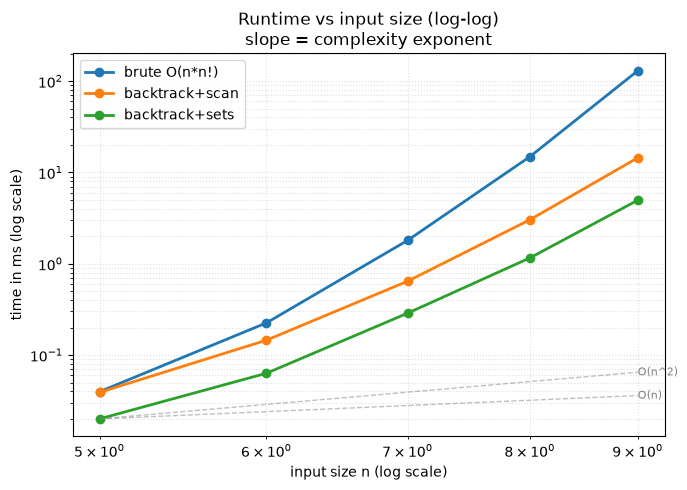

{'brute O(n*n!)': [0.03966700751334429,
  0.2251660916954279,
  1.8015829846262932,
  14.881500042974949,
  129.82412497512996],
 'backtrack+scan': [0.03900006413459778,
  0.14545803423970938,
  0.6436669500544667,
  3.0318329809233546,
  14.449500013142824],
 'backtrack+sets': [0.020000035874545574,
  0.06316602230072021,
  0.28737494722008705,
  1.1583749437704682,
  4.961083992384374]}

In [6]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark

def make_worst_case(n):
    return (n,)                                  # the board size is the whole input

solutions = {
    "brute O(n*n!)": solve_n_queens_brute,
    "backtrack+scan": solve_n_queens_scan,
    "backtrack+sets": solve_n_queens_sets,
}
sizes = [5, 6, 7, 8, 9]                          # +1 per step, not doubling

benchmark(solutions, make_worst_case, sizes, repeats=3, plot=True)

## 🧩 Patterns Learned

- **Pattern:** [Partition and Placement](README.md) — the state is the row that needs a queen; each step chooses a column, rejects it with three `O(1)` set lookups if attacked, recurses to the next row, then removes the queen from the board **and** all three sets.
- **Diagonal ids:** `r - c` is constant along a `\` diagonal and `r + c` along a `/` diagonal. Two sets of integers replace any diagonal scan.
- **Shrink the search before searching:** "one queen per row" turns "pick `n` of the `n²` squares" into "pick one of `n` columns, row by row", and the prune removes attacked columns before recursing. The benchmark shows the brute force growing about `n×` per extra row while the set-based backtracking grows noticeably slower.
- **Undo everything you did:** the un-choose line mirrors the choose line exactly (`cols`, `diag`, `anti`, `board`). Missing one leaves a phantom queen that blocks later branches.
- **Signal:** "place `k` items on a board / in slots so that no two conflict, return all arrangements" — Sudoku Solver, N-Queens II (count only), graph colouring.
- **Related problems:** N-Queens II (return `len(out)` or a counter instead of boards), Sudoku Solver (choose a digit per empty cell, check row/column/box sets), Palindrome Partitioning (same choose-check-recurse shape on a string).
- **Common pitfalls:**
  1. Checking only columns and one diagonal — both `r - c` and `r + c` are needed.
  2. Recording `board` itself instead of `["".join(row) for row in board]` — later moves overwrite the recorded answer.
  3. Forgetting to restore `board[r][c] = "."` when un-choosing — the next solution shows two queens in that row.